# Motor parameter identification — TRIK RK370
After the experiment we compare the recorded data with the first-order model of the DC motor and find its parameters $T_m$ and $k_e$ for both drive wheels.

The robot stands on a support so **both wheels spin freely in the air**. The block program `motor_identification.qrs` drives M3 and M4 together with the same PWM, from −100 % to +100 % in steps of 5 %. Each level runs for 2 s; the samples are kept in a string variable and written to `motor_data.txt` once per level, **after** the motors are stopped (no file I/O inside the sampling loop). One line per sample:

| column | meaning | unit |
|---|---|---|
| 0 | PWM setpoint | % |
| 1 | time since the step was applied | ms |
| 2 | encoder E3 — wheel 1 (left, motor M3) | deg |
| 3 | encoder E4 — wheel 2 (right, motor M4) | deg |
| 4 | battery voltage | V |

The model (inductance neglected):
$$T_m\,\dot\omega + \omega = \frac{U}{k_e}, \qquad \dot\theta = \omega, \qquad U = \frac{PWM}{100}\,U_{bat}$$

In [1]:
try:
    from google.colab import files    # file work module
    uploaded = files.upload()         # upload motor_data.txt in Colab
except ImportError:
    pass                              # running locally: the file is next to the notebook

## Reading the data
The TRIK block language has no access to the battery, so the program logged `0` in the last column. The voltage is therefore set here by hand — **the value read on the robot before the run**. It only scales $U$ (and so $k_e$); $T_m$ and $\omega_{ss}$ do not depend on it.

The file holds all levels one after another, so we split it into runs wherever the PWM changes and convert to SI units.

In [2]:
import os
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver

DATA_FILE = 'motor_data.txt'        # raw file exactly as the robot wrote it
BATTERY_V = 11.1                    # V  <-- voltage shown on the robot before the run
WHEELS = {1: 'E3 (left, M3)', 2: 'E4 (right, M4)'}

data = np.loadtxt(DATA_FILE, comments='#')            # pwm, t_ms, enc3, enc4, batt
pwm_all, t_all, e3_all, e4_all, bat_all = data.T
if np.all(bat_all == 0):
    bat_all = np.full_like(bat_all, BATTERY_V)        # battery not logged -> use the value read on the robot

runs = []
start = 0
for i in range(1, len(pwm_all) + 1):                   # a new run starts where the PWM changes
    if i == len(pwm_all) or pwm_all[i] != pwm_all[i - 1]:
        sl = slice(start, i)
        runs.append({
            'pwm': int(pwm_all[start]),
            'U': pwm_all[start] / 100 * np.median(bat_all[sl]),   # applied voltage, V
            't': t_all[sl] / 1000,                                # s
            1: np.radians(e3_all[sl]),                            # wheel 1 angle, rad
            2: np.radians(e4_all[sl]),                            # wheel 2 angle, rad
        })
        start = i

print(len(runs), 'runs, PWM', runs[0]['pwm'], '...', runs[-1]['pwm'])
dt = np.concatenate([np.diff(r['t']) for r in runs]) * 1000
print('samples per run: %d-%d, sample period: median %.1f ms, max %.1f ms'
      % (min(len(r['t']) for r in runs), max(len(r['t']) for r in runs), np.median(dt), dt.max()))

41 runs, PWM -100 ... 100
samples per run: 34-48, sample period: median 41.7 ms, max 130.7 ms


A few raw step responses. The curve first bends (the motor accelerates) and then becomes a straight line — its slope is the steady-state speed $\omega_{ss}$.

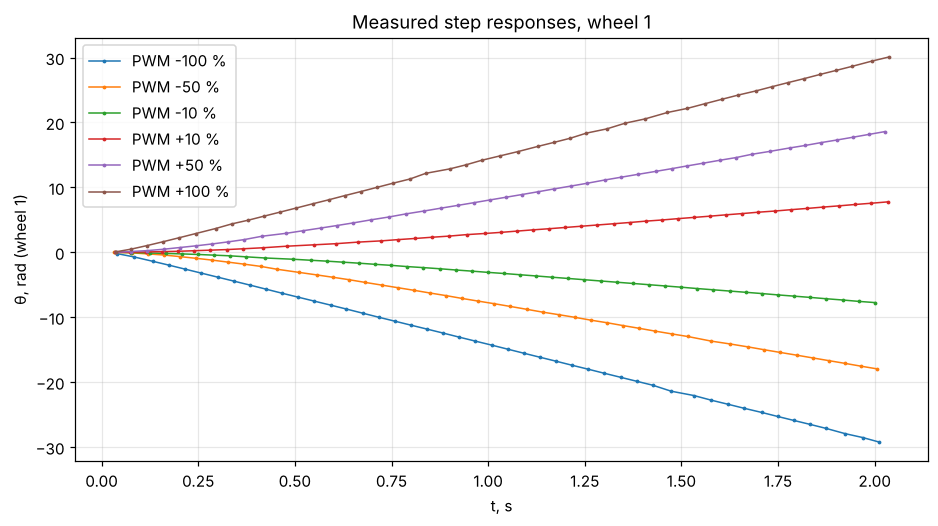

In [3]:
plt.figure(figsize=(10, 5), dpi=110)
for p in (-100, -50, -10, 10, 50, 100):
    r = next(r for r in runs if r['pwm'] == p)
    plt.plot(r['t'], r[1], '.-', ms=3, lw=1, label=f'PWM {p:+d} %')
plt.xlabel('t, s'); plt.ylabel('θ, rad (wheel 1)'); plt.grid(alpha=.3); plt.legend()
plt.title('Measured step responses, wheel 1')
plt.show()

## Fitting every run
For a voltage step from rest the angle is
$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}$$
We fit $\omega_{ss}$ and $T_m$ with *optimize.curve_fit*. The initial speed guess is the slope of the last part of the run, so the same code works for every level and both directions. A run where the wheel turned less than 15° counts as "did not move" (dead zone).

In [4]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)   # angle equation

def fit_run(t, ang):
    ang = ang - ang[0]
    if abs(np.degrees(ang[-1])) < 15:                                 # wheel did not move
        return 0.0, np.nan
    tail = t > t[-1] * 0.7                                            # last 30 % of the run
    speed0 = np.polyfit(t[tail], ang[tail], 1)[0]                     # initial guess from the data
    popt, _ = optimize.curve_fit(model, t, ang, p0=[speed0, 0.1],
                                 bounds=([-np.inf, 1e-3], [np.inf, 2]))  # T_m must stay positive
    return popt

pwm = np.array([r['pwm'] for r in runs])
U = np.array([r['U'] for r in runs])
w_ss, T_m = {}, {}
for wh in WHEELS:
    res = np.array([fit_run(r['t'], r[wh]) for r in runs])
    w_ss[wh], T_m[wh] = res[:, 0], res[:, 1]

for i in range(0, len(runs), 5):
    print('PWM %4d %%  U = %6.2f V | wheel 1: w_ss = %6.2f rad/s, T_m = %.3f s | wheel 2: w_ss = %6.2f rad/s, T_m = %.3f s'
          % (pwm[i], U[i], w_ss[1][i], T_m[1][i], w_ss[2][i], T_m[2][i]))

PWM -100 %  U = -11.10 V | wheel 1: w_ss = -14.84 rad/s, T_m = 0.058 s | wheel 2: w_ss = -14.03 rad/s, T_m = 0.064 s
PWM  -75 %  U =  -8.32 V | wheel 1: w_ss = -12.58 rad/s, T_m = 0.122 s | wheel 2: w_ss = -11.49 rad/s, T_m = 0.103 s
PWM  -50 %  U =  -5.55 V | wheel 1: w_ss = -10.17 rad/s, T_m = 0.239 s | wheel 2: w_ss =  -8.85 rad/s, T_m = 0.112 s
PWM  -25 %  U =  -2.77 V | wheel 1: w_ss =  -7.21 rad/s, T_m = 0.109 s | wheel 2: w_ss =  -6.14 rad/s, T_m = 0.062 s
PWM    0 %  U =   0.00 V | wheel 1: w_ss =   0.00 rad/s, T_m = nan s | wheel 2: w_ss =   0.00 rad/s, T_m = nan s
PWM   25 %  U =   2.77 V | wheel 1: w_ss =   7.47 rad/s, T_m = 0.338 s | wheel 2: w_ss =   6.32 rad/s, T_m = 0.289 s
PWM   50 %  U =   5.55 V | wheel 1: w_ss =  10.30 rad/s, T_m = 0.224 s | wheel 2: w_ss =   9.23 rad/s, T_m = 0.210 s
PWM   75 %  U =   8.32 V | wheel 1: w_ss =  12.72 rad/s, T_m = 0.132 s | wheel 2: w_ss =  11.98 rad/s, T_m = 0.116 s
PWM  100 %  U =  11.10 V | wheel 1: w_ss =  15.19 rad/s, T_m = 0.058

Check: every fitted curve (dashed) over its measurement.

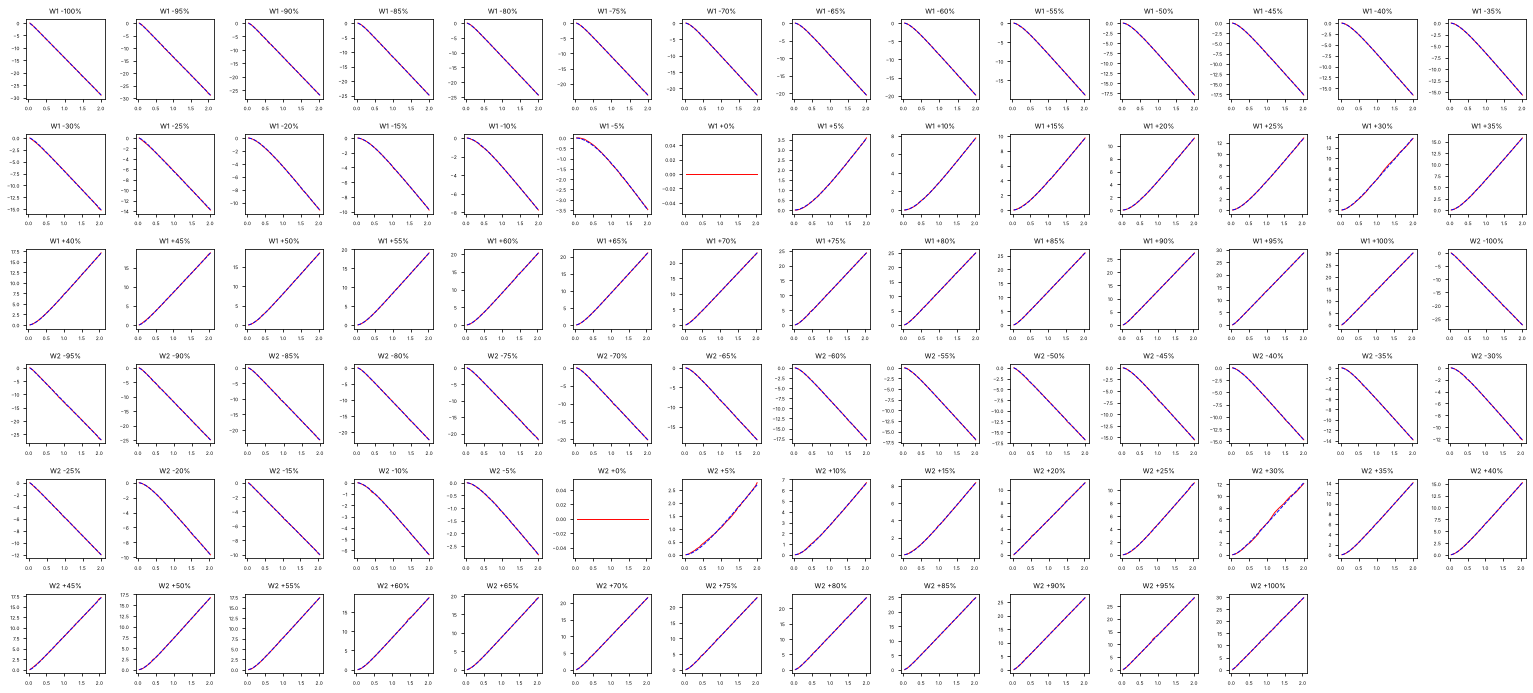

In [5]:
fig, axs = plt.subplots(6, 14, figsize=(22, 10), dpi=70)
k = 0
for wh in WHEELS:
    for i, r in enumerate(runs):
        ax = axs.flat[k]; k += 1
        ang = r[wh] - r[wh][0]
        ax.plot(r['t'], ang, 'r-', lw=1)
        if not np.isnan(T_m[wh][i]):
            ax.plot(r['t'], model(r['t'], w_ss[wh][i], T_m[wh][i]), 'b--', lw=1)
        ax.set_title(f'W{wh} {r["pwm"]:+d}%', fontsize=7); ax.tick_params(labelsize=5)
for ax in axs.flat[k:]:
    ax.axis('off')
plt.tight_layout(); plt.show()

## Results for the report
Everything below is written to `report_figs/`.

**Table** of $T_m$ and $\omega_{ss}$ for every PWM level, both wheels.

In [6]:
os.makedirs('report_figs', exist_ok=True)
lines = ['| PWM, % | U, V | ω_ss wheel 1, rad/s | T_m wheel 1, s | ω_ss wheel 2, rad/s | T_m wheel 2, s |',
         '|---:|---:|---:|---:|---:|---:|']
f = lambda x, d: '—' if np.isnan(x) else f'{x:.{d}f}'
for i in range(len(runs)):
    lines.append(f'| {pwm[i]} | {U[i]:.2f} | {f(w_ss[1][i], 2)} | {f(T_m[1][i], 3)} | {f(w_ss[2][i], 2)} | {f(T_m[2][i], 3)} |')
open('report_figs/table.md', 'w').write('\n'.join(lines) + '\n')
print('\n'.join(lines[:6]), '\n...')

| PWM, % | U, V | ω_ss wheel 1, rad/s | T_m wheel 1, s | ω_ss wheel 2, rad/s | T_m wheel 2, s |
|---:|---:|---:|---:|---:|---:|
| -100 | -11.10 | -14.84 | 0.058 | -14.03 | 0.064 |
| -95 | -10.54 | -14.46 | 0.067 | -13.58 | 0.060 |
| -90 | -9.99 | -13.81 | 0.085 | -12.81 | 0.078 |
| -85 | -9.43 | -13.19 | 0.117 | -12.13 | 0.090 | 
...


**$k_e$.** By the model $\omega_{ss} = U/k_e$, so $k_e$ is the slope of $U$ against $\omega_{ss}$ through the origin. We fit it by least squares, $k_e = \sum U^2 / \sum U\omega_{ss}$, over $|PWM| \ge 30\,\%$ — below that, friction bends the curve — for both directions together, forward and reverse. $T_m$ is summarised by the median over the same runs.

In [7]:
MIN_PWM = 30
def k_e_fit(w, m):
    return np.sum(U[m] ** 2) / np.sum(U[m] * w[m])                    # least squares, line through 0

summary = {}
for wh in WHEELS:
    w = w_ss[wh]
    moved = w != 0
    hi = moved & (np.abs(pwm) >= MIN_PWM)
    still = ~moved & (pwm != 0)
    summary[wh] = {
        'k_e': k_e_fit(w, hi), 'k_e_fwd': k_e_fit(w, hi & (pwm > 0)), 'k_e_rev': k_e_fit(w, hi & (pwm < 0)),
        'T_m': np.nanmedian(T_m[wh][hi]), 'T_m_min': np.nanmin(T_m[wh][hi]), 'T_m_max': np.nanmax(T_m[wh][hi]),
        'dead': (pwm[still].min() if still.any() else 0, pwm[still].max() if still.any() else 0),
    }
    s = summary[wh]
    print(f"wheel {wh} {WHEELS[wh]}: k_e = {s['k_e']:.3f} V·s/rad (fwd {s['k_e_fwd']:.3f}, rev {s['k_e_rev']:.3f}), "
          f"T_m = {s['T_m']:.3f} s (range {s['T_m_min']:.3f}-{s['T_m_max']:.3f}), "
          f"dead zone: {'none at ±5 %' if s['dead'] == (0, 0) else s['dead']}")

wheel 1 E3 (left, M3): k_e = 0.653 V·s/rad (fwd 0.647, rev 0.658), T_m = 0.149 s (range 0.058-0.282), dead zone: none at ±5 %
wheel 2 E4 (right, M4): k_e = 0.705 V·s/rad (fwd 0.688, rev 0.724), T_m = 0.126 s (range 0.055-0.255), dead zone: none at ±5 %


**$\omega_{ss}$ against the actual voltage**, both wheels on the same axes, with the fitted $k_e$ lines. Levels where a wheel did not move would be marked as the dead zone; with the wheels in the air both already turn at ±5 %.

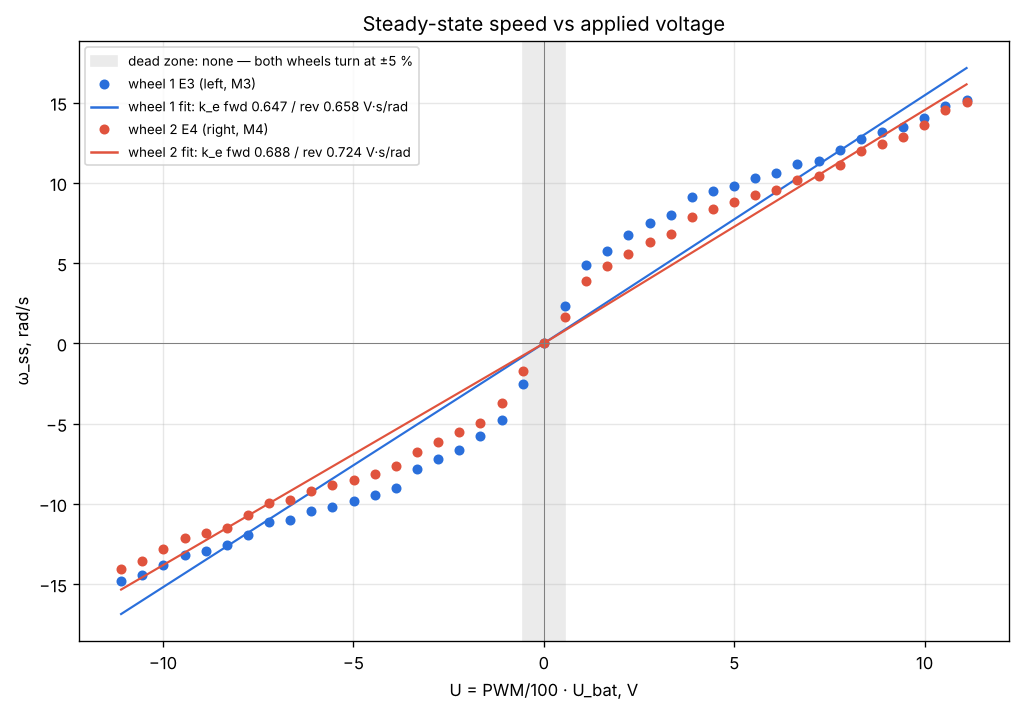

In [8]:
colors = {1: '#2a6fdb', 2: '#e0533d'}
plt.figure(figsize=(10, 6.5), dpi=120)
dz = [summary[wh]['dead'] for wh in WHEELS]
lo, hi_ = min(d[0] for d in dz), max(d[1] for d in dz)
if lo or hi_:
    plt.axvspan(lo / 100 * BATTERY_V, hi_ / 100 * BATTERY_V, color='0.85', label='dead zone (no rotation)')
else:
    plt.axvspan(-0.05 * BATTERY_V, 0.05 * BATTERY_V, color='0.92',
                label='dead zone: none — both wheels turn at ±5 %')
for wh in WHEELS:
    s = summary[wh]
    plt.plot(U, w_ss[wh], 'o', color=colors[wh], ms=5, label=f'wheel {wh} {WHEELS[wh]}')
    for side, key in ((1, 'k_e_fwd'), (-1, 'k_e_rev')):
        u = np.linspace(0, side * np.abs(U).max(), 10)
        plt.plot(u, u / s[key], '-', color=colors[wh], lw=1.3)
    plt.plot([], [], '-', color=colors[wh], label=f"wheel {wh} fit: k_e fwd {s['k_e_fwd']:.3f} / rev {s['k_e_rev']:.3f} V·s/rad")
plt.axhline(0, color='0.5', lw=.6); plt.axvline(0, color='0.5', lw=.6)
plt.xlabel('U = PWM/100 · U_bat, V'); plt.ylabel('ω_ss, rad/s'); plt.grid(alpha=.3)
plt.title('Steady-state speed vs applied voltage'); plt.legend(fontsize=8, loc='upper left')
plt.savefig('report_figs/omega_all_wheels.png', bbox_inches='tight'); plt.show()

**$T_m$ against voltage.** $T_m$ is clearly not constant: it is smallest at full power and grows towards low PWM.

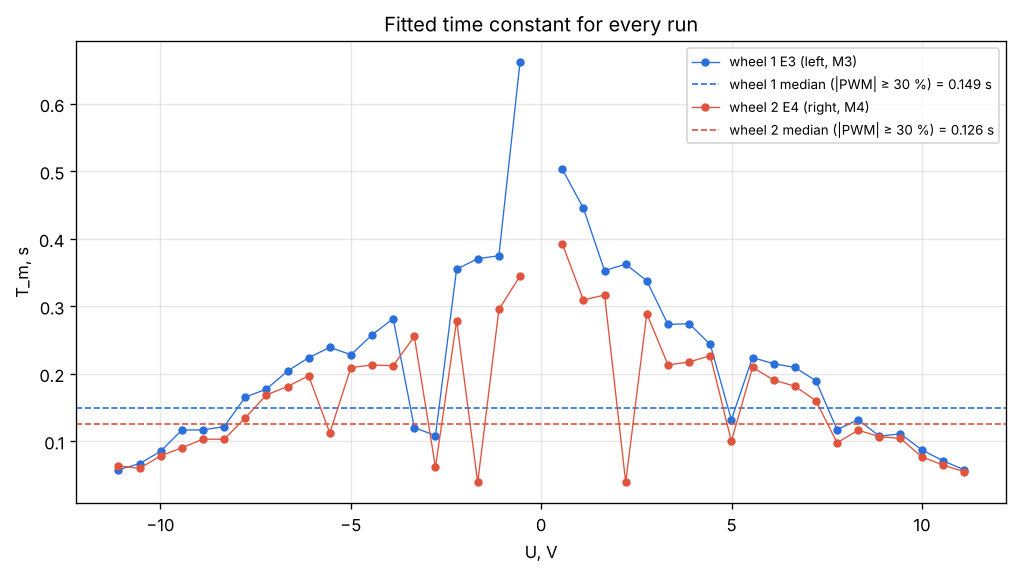

In [9]:
plt.figure(figsize=(10, 5), dpi=120)
for wh in WHEELS:
    plt.plot(U, T_m[wh], 'o-', color=colors[wh], ms=4, lw=.8, label=f'wheel {wh} {WHEELS[wh]}')
    plt.axhline(summary[wh]['T_m'], color=colors[wh], ls='--', lw=1,
                label=f"wheel {wh} median (|PWM| ≥ {MIN_PWM} %) = {summary[wh]['T_m']:.3f} s")
plt.xlabel('U, V'); plt.ylabel('T_m, s'); plt.grid(alpha=.3); plt.legend(fontsize=8)
plt.title('Fitted time constant for every run')
plt.savefig('report_figs/T_m.png', bbox_inches='tight'); plt.show()

## Simulating the identified motor
Numerical model of the motor, integrated with *odeint*:
$$\dot\omega = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \dot\theta = \omega$$
We run it with each wheel's identified $T_m$ (median) and $k_e$ for the run's direction, and compare it with the measurement at PWM = 100 % and 50 %.

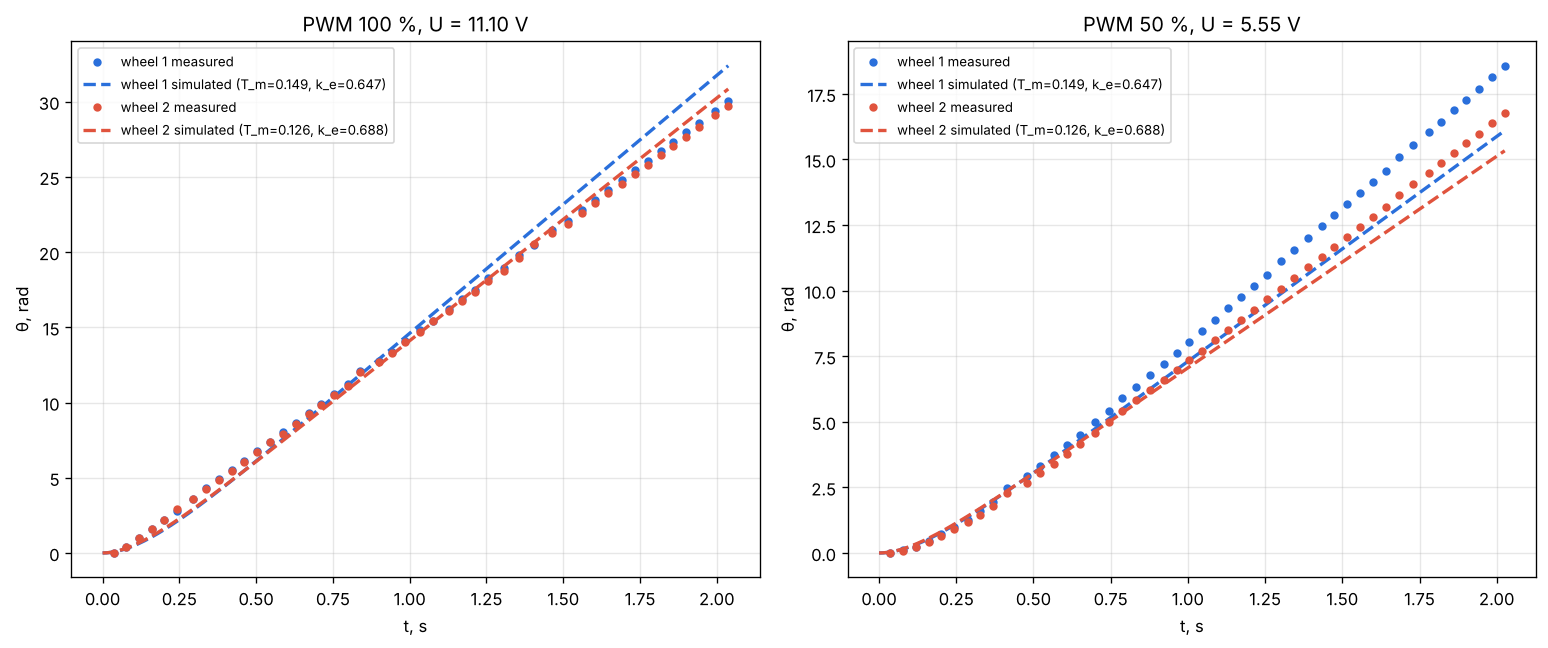

In [10]:
def motor(state, t, u, T_m, k_e):
    speed, angle = state                                              # motor state space
    return [-speed / T_m + u / (T_m * k_e), speed]                   # differential equations

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), dpi=120)
for ax, p in zip(axs, (100, 50)):
    r = next(r for r in runs if r['pwm'] == p)
    t_sim = np.linspace(0, r['t'][-1], 300)
    for wh in WHEELS:
        s = summary[wh]
        sim = odeint(motor, [0, 0], t_sim, args=(r['U'], s['T_m'], s['k_e_fwd']))[:, 1]
        ax.plot(r['t'], r[wh] - r[wh][0], 'o', color=colors[wh], ms=4, label=f'wheel {wh} measured')
        ax.plot(t_sim, sim, '--', color=colors[wh], lw=2,
                label=f"wheel {wh} simulated (T_m={s['T_m']:.3f}, k_e={s['k_e_fwd']:.3f})")
    ax.set_title(f'PWM {p} %, U = {r["U"]:.2f} V'); ax.set_xlabel('t, s'); ax.set_ylabel('θ, rad')
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/step_response.png', bbox_inches='tight'); plt.show()

## Wheel difference and the linear model
How much the two wheels differ at the same command, and what that would do to a differential-drive robot driving "straight" open loop. Wheel radius and track width as in the course odometry code — check them against your robot.

In [11]:
r_wheel, W = 0.0375, 0.194                                            # wheel radius, track width, m
for p in (100, 70, 50, 30, 10, -10, -30, -50, -70, -100):
    i = list(pwm).index(p)
    w1, w2 = w_ss[1][i], w_ss[2][i]
    diff = 100 * (abs(w1) - abs(w2)) / ((abs(w1) + abs(w2)) / 2)      # wheel 1 vs wheel 2, %
    v = r_wheel * (w1 + w2) / 2                                       # forward speed, m/s
    yaw = np.degrees(r_wheel * (w2 - w1) / W)                         # deg/s, + = turning left
    print(f'PWM {p:4d}: w1 = {w1:6.2f}, w2 = {w2:6.2f} rad/s, diff = {diff:+5.1f} %, '
          f'yaw = {yaw:+6.1f} deg/s, heading drift = {yaw / abs(v):+5.0f} deg per metre')

print('\nlinear model error, wheel 1 (fwd k_e):')
for p in (5, 10, 20, 30, 50, 100):
    i = list(pwm).index(p)
    pred = U[i] / summary[1]['k_e_fwd']
    print(f'PWM {p:3d} %: measured {w_ss[1][i]:6.2f}, model {pred:6.2f} rad/s, error {100 * (pred - w_ss[1][i]) / w_ss[1][i]:+5.0f} %')

PWM  100: w1 =  15.19, w2 =  15.02 rad/s, diff =  +1.1 %, yaw =   -1.9 deg/s, heading drift =    -3 deg per metre
PWM   70: w1 =  12.05, w2 =  11.14 rad/s, diff =  +7.9 %, yaw =  -10.2 deg/s, heading drift =   -23 deg per metre
PWM   50: w1 =  10.30, w2 =   9.23 rad/s, diff = +11.0 %, yaw =  -11.9 deg/s, heading drift =   -32 deg per metre
PWM   30: w1 =   8.00, w2 =   6.82 rad/s, diff = +15.8 %, yaw =  -13.0 deg/s, heading drift =   -47 deg per metre
PWM   10: w1 =   4.88, w2 =   3.86 rad/s, diff = +23.3 %, yaw =  -11.3 deg/s, heading drift =   -69 deg per metre
PWM  -10: w1 =  -4.76, w2 =  -3.75 rad/s, diff = +23.8 %, yaw =  +11.2 deg/s, heading drift =   +70 deg per metre
PWM  -30: w1 =  -7.85, w2 =  -6.76 rad/s, diff = +14.9 %, yaw =  +12.0 deg/s, heading drift =   +44 deg per metre
PWM  -50: w1 = -10.17, w2 =  -8.85 rad/s, diff = +13.9 %, yaw =  +14.6 deg/s, heading drift =   +41 deg per metre
PWM  -70: w1 = -11.93, w2 = -10.72 rad/s, diff = +10.7 %, yaw =  +13.4 deg/s, heading dr